In [1]:
import sqlite3
import pandas as pd

# 1. Connect to your database file
conn = sqlite3.connect("../data/metadata.db")

# 2. See what tables are inside
tables_df = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table';", conn
)
print("Tables in your database:")
print(tables_df)

# 3. Load a table into a pandas DataFrame (like a CSV)
# Replace 'metadata' or the other table name with what appears in your tables list
df_metadata = pd.read_sql_query("SELECT * FROM metadata", conn)

# Close connection when done
conn.close()

# 4. Explore just like a CSV!
print("\nFirst few rows of the metadata table:")
print(df_metadata.head())

Tables in your database:
       name
0  metadata

First few rows of the metadata table:
        name                                           metadata
0  00001.jpg  {"BIN_FCSKU_DATA": {"B000C33MI2": {"asin": "B0...
1      1.jpg  {"BIN_FCSKU_DATA": {}, "EXPECTED_QUANTITY": 0,...
2  00002.jpg  {"BIN_FCSKU_DATA": {"0307981584": {"asin": "03...
3      2.jpg  {"BIN_FCSKU_DATA": {}, "EXPECTED_QUANTITY": 0,...
4  00003.jpg  {"BIN_FCSKU_DATA": {"0307981584": {"asin": "03...


In [2]:
import sqlite3, json
import pandas as pd

conn = sqlite3.connect("../data/metadata.db")
rows = []

for bin_id, meta in conn.execute("SELECT name, metadata FROM metadata"):
    d = json.loads(meta)
    total = d.get("EXPECTED_QUANTITY", 0)
    for asin, item in d.get("BIN_FCSKU_DATA", {}).items():
        rows.append((bin_id, total, asin, item.get("name"), item.get("quantity")))

conn.close()

df = pd.DataFrame(rows, columns=["bin_id", "total_qty", "asin", "product_name", "qty"])
df.to_csv("../data/bin_items.csv", index=False)
print(df.shape)
df.head()

(1415744, 5)


,bin_id,total_qty,asin,product_name,qty
0,00001.jpg,12,B000C33MI2,FRAM XG7317 ULTRA Spin-On Oil Filter with Sure...,4
1,00001.jpg,12,B0050Z27KG,Suncatcher - Axicon Rainbow Window - Includes ...,2
2,00001.jpg,12,B01BV89HNU,"Type C, iOrange-E 2 Pack 6.6 Ft Braided Cable ...",6
3,00002.jpg,17,0307981584,Thomas Saves Easter! (Thomas & Friends) (Glitt...,13
4,00002.jpg,17,B000052XHI,"First Response Early Result Pregnancy Test, 3 ...",2


In [3]:
# Total units per bin, from the product rows
sums = df.groupby("bin_id")["qty"].sum()

# Keep bins with 1 to 5 units where product quantities add up to the total
ok = df.groupby("bin_id")["total_qty"].first()
good_bins = ok[(ok >= 1) & (ok <= 5) & (sums == ok)].index

good = df[df["bin_id"].isin(good_bins)]
print("Usable bins:", good["bin_id"].nunique())

# How many bins does each product appear in?
freq = good.groupby("asin")["bin_id"].nunique().sort_values(ascending=False)
print("Products seen:", len(freq))
print("Products in 100+ bins:", (freq >= 100).sum())
print("Products in 50+ bins:", (freq >= 50).sum())
print(freq.head(10))

Usable bins: 351957
Products seen: 313333
Products in 100+ bins: 57
Products in 50+ bins: 400
asin
B013UJS35G    476
B00O4OR4GQ    298
B019D9HESO    257
B0159A0LH2    256
B01B1GE6KG    245
B01DV2OJYG    230
B00O7CM12W    214
B0002YKBV2    210
B015QWHXWE    203
B01FZ0WP3E    198
Name: bin_id, dtype: int64


In [4]:
for n in [10, 15, 20, 30, 40, 57]:
    cat = set(freq.index[:n])
    sub = good[good["asin"].isin(cat)]
    print(n, "products ->", sub["bin_id"].nunique(), "bins contain at least one")

10 products -> 2586 bins contain at least one
15 products -> 3514 bins contain at least one
20 products -> 4329 bins contain at least one
30 products -> 5725 bins contain at least one
40 products -> 6936 bins contain at least one
57 products -> 8738 bins contain at least one


In [5]:
print(freq.iloc[[9, 14, 19, 24, 29]])

asin
B01FZ0WP3E    198
B005KG7EDU    177
B003OGKCDC    156
B00IT1RELU    143
B018K8UGKM    132
Name: bin_id, dtype: int64


In [6]:
import numpy as np
rng = np.random.default_rng(42)   # fixed seed so the pick is repeatable

N = 15
catalogue = list(freq.index[:N])
sub = good[good["asin"].isin(catalogue)]
bins_of = sub.groupby("asin")["bin_id"].apply(set)

selected = set()

# Step 1: make sure every product gets 100 photos, rarest product first
for asin in reversed(catalogue):
    need = 100 - len(bins_of[asin] & selected)
    if need > 0:
        pool = sorted(bins_of[asin] - selected)
        selected.update(rng.choice(pool, size=need, replace=False))

# Step 2: fill up to 2,000 with other photos that contain catalogue products
rest = sorted(set(sub["bin_id"]) - selected)
selected.update(rng.choice(rest, size=2000 - len(selected), replace=False))

print("Selected bins:", len(selected))
print(sub[sub["bin_id"].isin(selected)].groupby("asin")["bin_id"].nunique().sort_values())

Selected bins: 2000
asin
B005KG7EDU    119
B00Q2VIW9M    123
B015TC63LI    124
B00O9GW8TC    125
B015QWHXWE    125
B014TE51C4    126
B0002YKBV2    127
B019D9HESO    128
B01FZ0WP3E    131
B00O7CM12W    132
B01DV2OJYG    133
B0159A0LH2    138
B01B1GE6KG    142
B00O4OR4GQ    156
B013UJS35G    177
Name: bin_id, dtype: int64


In [7]:
import os
os.makedirs("../data/prepared", exist_ok=True)

# 1. catalogue.csv: one row per product
cat_names = (good[good["asin"].isin(catalogue)]
             .drop_duplicates("asin")
             .set_index("asin")["product_name"])
cat_df = pd.DataFrame({"asin": catalogue,
                       "product_name": [cat_names[a] for a in catalogue],
                       "bins_in_subset": [int(sub[sub["bin_id"].isin(selected)]
                                              .query("asin == @a")["bin_id"].nunique())
                                          for a in catalogue]})
cat_df.to_csv("../data/prepared/catalogue.csv", index=False)

# 2. selected_bins.csv: one row per bin, one column per product (units found)
chosen = sub[sub["bin_id"].isin(selected)]
labels = chosen.pivot_table(index="bin_id", columns="asin", values="qty",
                            aggfunc="sum", fill_value=0)[catalogue]
labels.to_csv("../data/prepared/selected_bins.csv")

print(cat_df)
print(labels.shape)      # should be (2000, 15)
print(labels.head())

          asin                                       product_name  \
0   B013UJS35G  TaoTronics TT-AH002 30W Ultrasonic Humidifier ...   
1   B00O4OR4GQ  Fujifilm Instax Mini Instant Film (3 Twin Pack...   
2   B019D9HESO                                RTIC 30 oz. Tumbler   
3   B0159A0LH2  Pumpkin Pie Quest Bars 2 Pack Total of 24 Coat...   
4   B01B1GE6KG  Laser Lights Outdoor Starry Projector Red and ...   
5   B01DV2OJYG         Best Microfiber Cleaning Cloth, Pack of 50   
6   B00O7CM12W  Lifetime Warranty FDA cleared OTC HealthmateFo...   
7   B0002YKBV2  3M 8511 Particulate N95 Respirator with Valve,...   
8   B015QWHXWE  UP2 by Jawbone Activity + Sleep Tracker, Light...   
9   B01FZ0WP3E  AuYou Wi-Fi Smart Outlet Switch, 5 Outlets Mul...   
10  B00Q2VIW9M  Bluedio Turbine T2s Wireless Bluetooth Headpho...   
11  B015TC63LI                My Little Pony POP and Starter Kits   
12  B014TE51C4  Angry Birds K'nex Mission Mayham & Hammin Arou...   
13  B00O9GW8TC  Nintendo Super Sma

In [8]:
labels = pd.read_csv("../data/prepared/selected_bins.csv", index_col=0)

rng = np.random.default_rng(42)          # fixed seed, so the split is repeatable
ids = np.array(sorted(labels.index))
rng.shuffle(ids)

split = pd.Series("train", index=ids)
split[ids[1400:1600]] = "validation"
split[ids[1600:1900]] = "test"
split[ids[1900:]]     = "blind"

split.rename("split").to_csv("../data/prepared/split.csv")

print(split.value_counts())
print("Overlap check (should be 2000):", split.index.nunique())

# how many bins have each product, in each group
present = (labels > 0).groupby(split).sum().T
print(present)

train         1400
test           300
validation     200
blind          100
Name: count, dtype: int64
Overlap check (should be 2000): 2000
            blind  test  train  validation
B013UJS35G      7    27    128          15
B00O4OR4GQ      7    21    110          18
B019D9HESO      3    21     89          15
B0159A0LH2     12    25     83          18
B01B1GE6KG      8    19    100          15
B01DV2OJYG      5    19     94          15
B00O7CM12W      8    19     88          17
B0002YKBV2      6    18     93          10
B015QWHXWE      6    20     89          10
B01FZ0WP3E     10    26     81          14
B00Q2VIW9M      7    22     83          11
B015TC63LI      6    14     90          14
B014TE51C4      6    18     92          10
B00O9GW8TC      7    14     92          12
B005KG7EDU      2    18     91           8


In [9]:
import shutil, os

SRC = "/Users/praneeth/Downloads/archive/bin-images-224x224/bin-images-224x224"   # <- change this
OUT = "../data/prepared"

split = pd.read_csv(f"{OUT}/split.csv", index_col=0)["split"]

for name in ["train", "validation", "test", "blind"]:
    os.makedirs(f"{OUT}/{name}", exist_ok=True)

for bin_id, grp in split.items():
    shutil.copy(f"{SRC}/{bin_id}", f"{OUT}/{grp}/{bin_id}")

for name in ["train", "validation", "test", "blind"]:
    print(name, len(os.listdir(f"{OUT}/{name}")))

train 1401
validation 201
test 301
blind 100


In [10]:
import hashlib

OUT = "../data/prepared"
labels = pd.read_csv(f"{OUT}/selected_bins.csv", index_col=0)
split = pd.read_csv(f"{OUT}/split.csv", index_col=0)["split"]

# 1. Label files (train, validation, test only; blind gets none)
for grp in ["train", "validation", "test"]:
    labels.loc[split[split == grp].index].to_csv(f"{OUT}/{grp}/labels.csv")

# 2. Duplicate check: fingerprint every photo, look for repeats across groups
fp = {}
for bin_id, grp in split.items():
    with open(f"{OUT}/{grp}/{bin_id}", "rb") as f:
        fp[bin_id] = hashlib.md5(f.read()).hexdigest()

fp = pd.Series(fp)
dups = fp[fp.duplicated(keep=False)]
print("Duplicate photos:", len(dups))
print(pd.DataFrame({"hash": dups, "split": split[dups.index]}).sort_values("hash"))

Duplicate photos: 0
Empty DataFrame
Columns: [hash, split]
Index: []


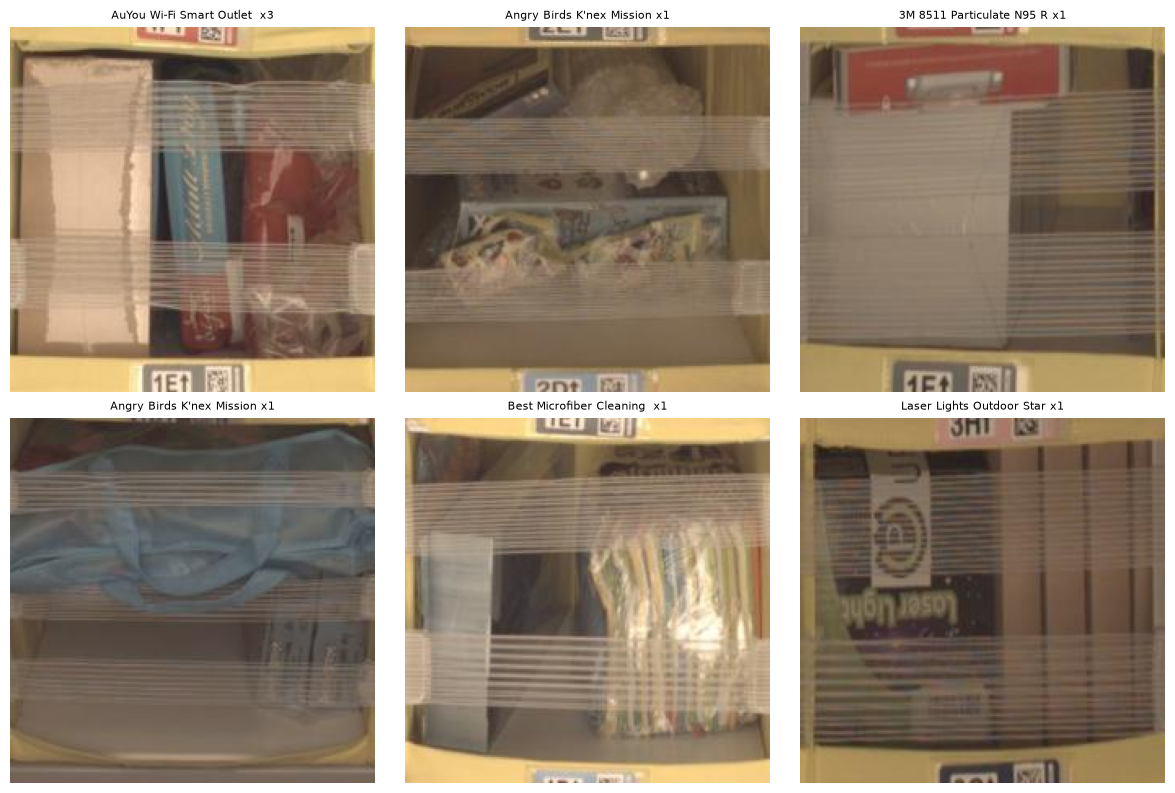

In [11]:
import matplotlib.pyplot as plt
from PIL import Image

OUT = "../data/prepared"
cat = pd.read_csv(f"{OUT}/catalogue.csv").set_index("asin")
train_labels = pd.read_csv(f"{OUT}/train/labels.csv", index_col=0)

sample = train_labels.sample(6, random_state=1)

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, (bin_id, row) in zip(axes.flat, sample.iterrows()):
    ax.imshow(Image.open(f"{OUT}/train/{bin_id}"))
    found = [f"{cat.loc[a, 'product_name'][:25]} x{q}" for a, q in row.items() if q > 0]
    ax.set_title("\n".join(found), fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

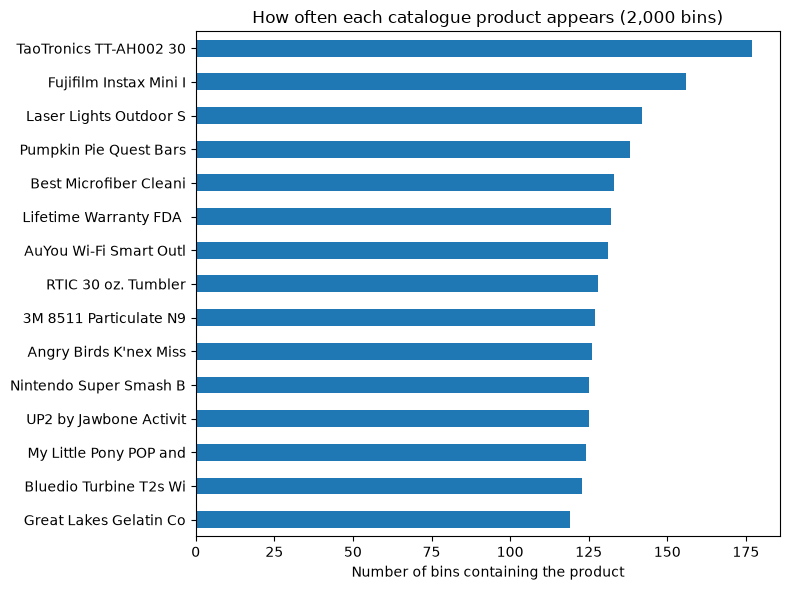

In [12]:
OUT = "../data/prepared"
labels = pd.read_csv(f"{OUT}/selected_bins.csv", index_col=0)
cat = pd.read_csv(f"{OUT}/catalogue.csv").set_index("asin")

# short names for the chart
short = {a: cat.loc[a, "product_name"][:22] for a in labels.columns}

counts = (labels > 0).sum().rename(index=short).sort_values()

counts.plot(kind="barh", figsize=(8, 6))
plt.xlabel("Number of bins containing the product")
plt.title("How often each catalogue product appears (2,000 bins)")
plt.tight_layout()
plt.show()

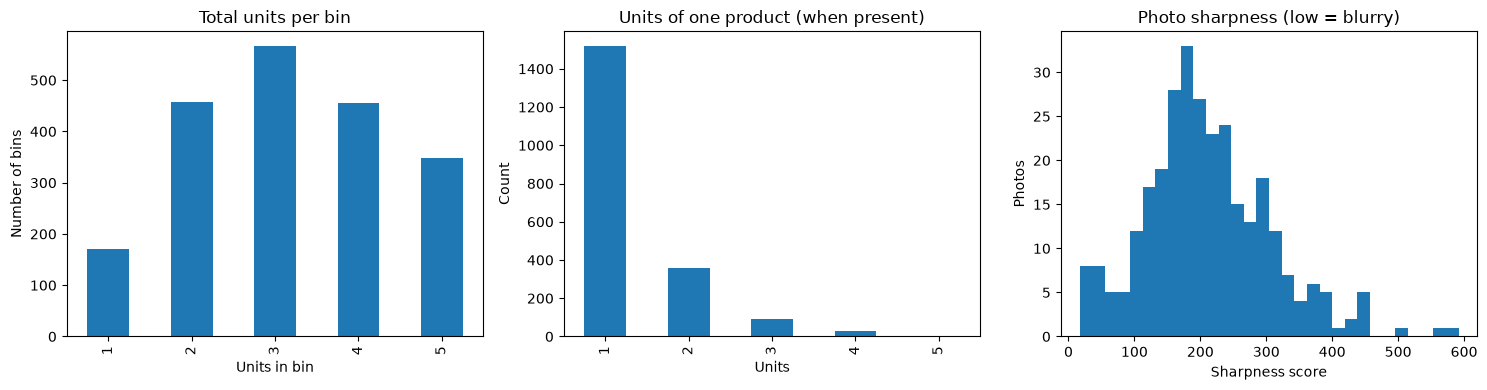

Bins with at least one non-catalogue unit: 86 %
Average non-catalogue units per bin: 1.85


In [13]:
import numpy as np
from PIL import Image


OUT = "../data/prepared"
labels = pd.read_csv(f"{OUT}/selected_bins.csv", index_col=0)
items = pd.read_csv("../data/bin_items.csv")

# total units in each bin (from the metadata, includes non-catalogue products)
tot = items.drop_duplicates("bin_id").set_index("bin_id")["total_qty"].loc[labels.index]

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

# Chart 2a: total units per bin
tot.value_counts().sort_index().plot(kind="bar", ax=ax[0])
ax[0].set_title("Total units per bin")
ax[0].set_xlabel("Units in bin"); ax[0].set_ylabel("Number of bins")

# Chart 2b: how many units of one product are in a bin (when present)
q = pd.Series(labels.values.flatten())
q[q > 0].value_counts().sort_index().plot(kind="bar", ax=ax[1])
ax[1].set_title("Units of one product (when present)")
ax[1].set_xlabel("Units"); ax[1].set_ylabel("Count")

# Chart 3: sharpness of 300 random training photos (low = blurry)
def sharp(path):
    g = np.asarray(Image.open(path).convert("L"), dtype=float)
    lap = 4*g[1:-1,1:-1] - g[:-2,1:-1] - g[2:,1:-1] - g[1:-1,:-2] - g[1:-1,2:]
    return lap.var()

train_ids = pd.read_csv(f"{OUT}/train/labels.csv", index_col=0).sample(300, random_state=1).index
scores = pd.Series({b: sharp(f"{OUT}/train/{b}") for b in train_ids})
ax[2].hist(scores, bins=30)
ax[2].set_title("Photo sharpness (low = blurry)")
ax[2].set_xlabel("Sharpness score"); ax[2].set_ylabel("Photos")

plt.tight_layout()
plt.show()

# Odd thing in the metadata: units that are NOT catalogue products
other = tot - labels.sum(axis=1)
print("Bins with at least one non-catalogue unit:", round((other > 0).mean() * 100), "%")
print("Average non-catalogue units per bin:", round(other.mean(), 2))

In [14]:
n_cat = (labels > 0).sum(axis=1)
print(n_cat.value_counts())

1    1994
2       6
Name: count, dtype: int64


In [15]:
import sqlite3, json

cat_df = pd.read_csv("../data/prepared/catalogue.csv")
wanted = set(cat_df["asin"])
info = {}

conn = sqlite3.connect("../data/metadata.db")
for _, meta in conn.execute("SELECT name, metadata FROM metadata"):
    for asin, item in json.loads(meta).get("BIN_FCSKU_DATA", {}).items():
        if asin in wanted and asin not in info:
            info[asin] = {k: (item.get(k) or {}).get("value")
                          for k in ["height", "length", "width", "weight"]}
    if len(info) == len(wanted):
        break
conn.close()

extra = pd.DataFrame(info).T.rename_axis("asin").reset_index()
cat_df = cat_df.drop(columns=[c for c in extra.columns if c != "asin" and c in cat_df.columns]).merge(extra, on="asin", how="left")
cat_df.to_csv("../data/prepared/catalogue.csv", index=False)
print(cat_df.drop(columns="product_name"))

          asin  bins_in_subset    height     length      width    weight
0   B013UJS35G             177  7.100000  14.500000  10.200000  4.200000
1   B00O4OR4GQ             156  2.100000   8.100000   5.200000  0.600000
2   B019D9HESO             128  4.200000   8.600000   4.200000  1.140000
3   B0159A0LH2             138  2.500000  11.900000   7.500000  3.300000
4   B01B1GE6KG             142  5.500000   7.500000   5.500000  1.350000
5   B01DV2OJYG             133  6.000000  12.000000   7.500000  1.900000
6   B00O7CM12W             132  1.500000   9.500000   7.100000  0.300000
7   B0002YKBV2             127  5.100000   8.700000   6.200000  0.500000
8   B015QWHXWE             125  2.300000   5.800000   5.000000  0.400000
9   B01FZ0WP3E             131  4.700000   9.100000   4.800000  1.200000
10  B00Q2VIW9M             123  3.543307   7.952756   6.850394  0.970024
11  B015TC63LI             124  3.500000   6.800000   6.100000  0.750000
12  B014TE51C4             126  4.400000  15.400000

In [16]:
items = pd.read_csv("../data/bin_items.csv", dtype={"asin": str})
split = pd.read_csv("../data/prepared/split.csv", index_col=0)
f = items[items["bin_id"].isin(split.index)].groupby("asin")["bin_id"].nunique().sort_values(ascending=False)
print((f >= 100).sum()); print(f.head(18))

15
asin
B013UJS35G    177
B00O4OR4GQ    156
B01B1GE6KG    142
B0159A0LH2    138
B01DV2OJYG    133
B00O7CM12W    132
B01FZ0WP3E    131
B019D9HESO    128
B0002YKBV2    127
B014TE51C4    126
B015QWHXWE    125
B00O9GW8TC    125
B015TC63LI    124
B00Q2VIW9M    123
B005KG7EDU    119
B004IW5ITO      4
B009QJLBDQ      4
B0195XNWWK      3
Name: bin_id, dtype: int64
